# Overview of Mislocalized Variants

In [24]:
import seaborn as sns
import numpy as np
import polars as pl
from tqdm import tqdm
import matplotlib.pyplot as plt
from pycytominer.feature_select import feature_select
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_distances
import networkx as nx
import community.community_louvain as community_louvain
from kneed import KneeLocator
import umap
import pandas as pd
from utils import inverse_normal_transform
# from adjustText import adjust_text
import igraph as ig
import leidenalg

sns.set_theme(style='white')

## 1. Loading Data

In [2]:
ref_var_cell_all_prof_df = pl.read_parquet("../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_gfp_feat_sc_cp_profiles_oneperc.parquet")
feat_df = pl.read_csv("../../3_outputs/feat_importance_gt1e-3_all_alleles.csv")

In [3]:
imaging_summary_clinvar = pl.read_csv("../../3_outputs/imaging_analyses_summary_clinvar.tsv", separator="\t", infer_schema_length=100000)
imaging_summary_clinvar_hits = imaging_summary_clinvar.filter(
    pl.col("Altered_95th_perc_both_batches_GFP"),
)
misloc_alleles = imaging_summary_clinvar_hits["gene_variant"].to_list()

## Protein abundance change
imaging_summary_clinvar_abund_chg = imaging_summary_clinvar.filter(
    (pl.col("U2OS_prot_abun_t_stat").is_not_null()) & (pl.col("U2OS_prot_abun_t_pval") < 0.05/943)
)
prot_abund_chg_alleles = imaging_summary_clinvar_abund_chg["gene_variant"].to_list()
print(len(misloc_alleles))

# ax = sns.regplot(
#     data=imaging_summary_clinvar.to_pandas(),
#     x="AUROC_Mean_GFP",
#     y="AUROC_Mean_GFP_ADJ"
# )
# ax.set_xlim(0.45, 1.05)
# ax.set_ylim(0.45, 1.05)
# plt.show()

# ax = sns.regplot(
#     data=imaging_summary_clinvar.filter(
#         (pl.col("AUROC_Mean_GFP")>.9) | (pl.col("AUROC_Mean_GFP_ADJ")>.9)
#     ).to_pandas(),
#     x="AUROC_Mean_GFP",
#     y="AUROC_Mean_GFP_ADJ"
# )
# ax.set_xlim(0.825, 1.005)
# ax.set_ylim(0.825, 1.005)
# plt.show()
imaging_summary_clinvar_hits

140


Gene,gene_variant,U2OS_cc_t_stat,U2OS_cc_t_pval,U2OS_prot_abun_t_stat,U2OS_prot_abun_t_orig_pval,U2OS_prot_abun_t_adj_pval,U2OS_prot_abun_t_pval,Metadata_Bio_Batch,Altered_95th_perc_both_batches_GFP_ADJ,Altered_95th_perc_both_batches_GFP,Altered_95th_perc_both_batches_DNA,Altered_95th_perc_both_batches_Mito,Altered_95th_perc_both_batches_AGP,Altered_95th_perc_both_batches_Morph,Altered_99th_perc_both_batches_GFP_ADJ,Altered_99th_perc_both_batches_GFP,Altered_99th_perc_both_batches_DNA,Altered_99th_perc_both_batches_Mito,Altered_99th_perc_both_batches_AGP,Altered_99th_perc_both_batches_Morph,AUROC_Mean_GFP_ADJ,AUROC_Mean_GFP,AUROC_Mean_DNA,AUROC_Mean_Mito,AUROC_Mean_AGP,AUROC_Mean_Morph,AUROC_BioRep1_Morph,AUROC_BioRep1_AGP,AUROC_BioRep1_Mito,AUROC_BioRep1_DNA,AUROC_BioRep1_GFP,AUROC_BioRep1_GFP_ADJ,AUROC_BioRep2_Morph,AUROC_BioRep2_AGP,AUROC_BioRep2_Mito,AUROC_BioRep2_DNA,…,g2p_O-GalNAc,g2p_O-GlcNAc,g2p_Peptide (UniProt),g2p_Phi angle (degrees)*,g2p_Phosphorylation,g2p_Pocket number (fpocket)*,g2p_Propeptide (UniProt),g2p_Psi angle (degrees)*,g2p_Region (UniProt),g2p_Regulatory sites,g2p_Repeat (UniProt),g2p_SNP-associated PTMs,g2p_SUMOylation,g2p_Secondary structure (DSSP 3-state)*,g2p_Secondary structure (DSSP 9-state)*,g2p_Secondary structure (PDBe/SIFTS),g2p_Sequence conflict (UniProt),g2p_Sequence uncertainty (UniProt),g2p_Signal (UniProt),g2p_Site (UniProt),g2p_Substrate genes,g2p_Topological domain (UniProt),g2p_Transit peptide (UniProt),g2p_Transmembrane (UniProt),g2p_Ubiquitination,g2p_Zinc finger (UniProt),plddt_f32,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant
str,str,f64,f64,f64,f64,f64,f64,str,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,str,str,str,f64,str,str,str,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,i64,str,bool
"""GFAP""","""GFAP_Asn77Ser""",0.602116,0.566081,9.583633,0.000028,0.000174,0.000174,"""2025_03_Batch_15-16""",true,true,false,false,false,false,false,false,false,false,false,false,0.978313,0.968469,0.585899,0.814176,0.867727,0.707895,0.613056,0.868296,0.737507,0.576605,0.960268,0.970341,0.802735,0.867159,0.890845,0.595192,…,null,null,null,-64.5,null,"""Pocket 5: Mean pLDDT: 80.91, V…",null,-39.8,"""Coil 1A""",null,null,"""dbSNP: rs58732244; Variant typ…",null,"""H (helix)""","""H (α-helix)""",null,null,null,null,null,null,null,null,null,null,null,90.75,62.42038,""">90""","""10-90""","""203450""","""autosomal dominant""","""OMIM""","""Rare genetic eye disease; Rare…",2,"""ALEXANDER DISEASE""",false
"""PLP1""","""PLP1_Thr147Pro""",-0.705846,0.506751,-1.52601,0.177857,0.220251,0.220251,"""2024_01_Batch_7-8""",true,true,false,false,false,false,true,true,false,false,false,false,0.994112,0.993713,0.554743,0.662553,0.610156,0.586708,0.595633,0.514452,0.643864,0.568457,0.989611,0.992722,0.577783,0.70586,0.681243,0.54103,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,90.83,33.802814,""">90""","""10-90""","""312080""","""x-linked recessive""","""OMIM""","""Rare genetic eye disease; Rare…",2,"""PELIZAEUS-MERZBACHER DISEASE""",false
"""NR0B1""","""NR0B1_Asn440Ile""",-3.257613,0.01391,-13.250179,0.000003,0.000038,0.000038,"""2025_03_Batch_15-16""",true,true,false,false,false,false,true,true,false,false,false,false,0.998136,0.9914,0.481305,0.778369,0.690655,0.622407,0.787776,0.765525,0.832189,0.561267,0.988554,0.997037,0.457038,0.615784,0.724548,0.401343,…,null,null,null,-84.0,null,null,null,131.3,null,null,null,null,null,"""C (loop/coil)""","""C (loop/coil)""",null,null,null,null,null,null,null,null,null,null,null,91.15,52.229298,""">90""","""10-90""","""300200""","""x-linked recessive""","""OMIM""","""Rare genetic gynecological and…",7,"""ADRENAL HYPOPLASIA, CONGENITAL""",f

## 2. Z-score

In [25]:
FEATURE_IMPORTANCE_THRES = 0.01

In [26]:
# TOP_NUM_FEAT_MISLOC_VAR = 5
# # Get top 10 for each variant with feature names
# top_feat_misloc_alleles = []
# for col in misloc_alleles:
#     top_feats = feat_df.filter(
#         pl.col(col).is_in(pl.col(col).top_k(TOP_NUM_FEAT_MISLOC_VAR))
#     ).select(["cp_feature", col])
#     # print(top_feats.sort(col))
#     top_feat_misloc_alleles.append(top_feats)
    
# # Start with all features and left join each variant's top 10
# result_df = feat_df.select("cp_feature").unique().sort("cp_feature")
# for i, col in enumerate(misloc_alleles):
#     result_df = result_df.join(top_feat_misloc_alleles[i], on="cp_feature", how="left")

# misloc_var_top10_feat_df = result_df.select(
#     ["cp_feature"] + misloc_alleles
# ).filter(
#     ~pl.all_horizontal(pl.all().exclude("cp_feature").is_null())
# )
# get_top_n_feats_misloc_alleles = misloc_var_top10_feat_df["cp_feature"].to_list()
# len(get_top_n_feats_misloc_alleles)

misloc_var_sig_feat_df = feat_df.filter(
    # pl.col(col).is_in(pl.col(col).top_k(TOP_NUM_FEAT_MISLOC_VAR))
    pl.max_horizontal(misloc_alleles) > FEATURE_IMPORTANCE_THRES
)
get_sig_feats_misloc_alleles = misloc_var_sig_feat_df["cp_feature"].to_list()

In [27]:
norm_vars_feat_df, norm_var_sc_feat_df = pl.DataFrame(), pl.DataFrame()
sig_diff_feat = [feat for feat in get_sig_feats_misloc_alleles if feat in ref_var_cell_all_prof_df.columns] #[feat for feat in get_top_feats if feat in ref_var_cell_all_prof_df.columns]

for gene in tqdm(imaging_summary_clinvar_hits["Gene"].unique().to_list()):
    gene_mean = ref_var_cell_all_prof_df.filter(pl.col("Metadata_gene_allele")==gene).select(sig_diff_feat).mean().to_numpy()[0].tolist()
    gene_std = ref_var_cell_all_prof_df.filter(pl.col("Metadata_gene_allele")==gene).select(sig_diff_feat).std().to_numpy()[0].tolist()

    # print(gene, np.mean(gene_mean), np.min(gene_std))
    z_norm_var_sc_feat_df = ref_var_cell_all_prof_df.filter(
        (pl.col("Metadata_gene_allele").str.starts_with(f"{gene}_"))
        &(pl.col("Metadata_gene_allele")!=gene)
        &(pl.col("Metadata_gene_allele").is_in(imaging_summary_clinvar_hits["gene_variant"].unique()))
    ).with_columns(
        [((pl.col(col) - pl.lit(gene_mean[i])) / pl.lit(gene_std[i])).alias(col)
        for i, col in enumerate(sig_diff_feat)]
    )
    norm_var_sc_feat_df = pl.concat([
        norm_var_sc_feat_df,
        z_norm_var_sc_feat_df
    ])
    z_norm_var_feat_df = z_norm_var_sc_feat_df.group_by(
        "Metadata_gene_allele", "Metadata_Plate", "Metadata_Well" ## aggregate by well first
    ).agg(
        pl.col(col).mean().alias(col)
        for col in sig_diff_feat
    ).group_by(
        "Metadata_gene_allele" ## aggregate by allele
    ).agg(
        pl.col(col).median().alias(col)
        for col in sig_diff_feat
    )#.to_pandas().set_index("Metadata_gene_allele")[sig_diff_feat]

    norm_vars_feat_df = pl.concat(
        [norm_vars_feat_df, z_norm_var_feat_df],
         how="diagonal"
    )

100%|██████████| 44/44 [00:10<00:00,  4.03it/s]


__Robust Feature Preprocessing__

To mitigate the impact of extreme outliers on downstream distance-based analyses (e.g., hierarchical clustering, PCA) while preserving the linear directionality and magnitude of biological perturbations, we applied a Winsorization (clipping) procedure to the feature Z-scores. Z-scores were thresholded at a minimum of -5 and a maximum of +5. This step affected less than 0.1% of the data points, predominantly capping extreme artifacts (e.g., $|Z| > 20$) that would otherwise disproportionately skew Euclidean distance calculations. Unlike rank-based normalizations, this approach retains the relative scale of significant feature variations, ensuring that strong biological signals remain quantitatively distinct from subtle fluctuations.

In [15]:
# Standardize the features before PCA
# var_zscore_feat_gfp_filtered_int_df = inverse_normal_transform(norm_vars_feat_df)
var_zscore_feat_gfp_filtered_int_df = norm_vars_feat_df.to_pandas().set_index("Metadata_gene_allele")

# 2. Apply Winsorization (Clipping)
# We clip values at -5 (lower) and +5 (upper)
var_zscore_feat_gfp_filtered_int_df = var_zscore_feat_gfp_filtered_int_df.clip(lower=-5, upper=5).reset_index()

## feature selection
var_zscore_feat_gfp_filtered_int_feat_sel_df = feature_select(
    var_zscore_feat_gfp_filtered_int_df, operation="variance_threshold"
)
var_zscore_feat_gfp_filtered_int_feat_sel_df = pl.DataFrame(
    feature_select(var_zscore_feat_gfp_filtered_int_feat_sel_df, operation="correlation_threshold")
)

## Append important medadata to data frame
cols = [
    "gene_variant",
    "Metadata_Bio_Batch",
    "AUROC_Mean_GFP",
    "AUROC_Mean_GFP_ADJ",
    "Altered_95th_perc_both_batches_GFP",
    "Altered_95th_perc_both_batches_GFP_ADJ",
    "clinvar_OMIM_id",
    "OMIM_IDs",
    "OMIM_disease_names",
]
var_zscore_feat_gfp_filtered_int_feat_sel_df = var_zscore_feat_gfp_filtered_int_feat_sel_df.join(
    imaging_summary_clinvar.select(cols).rename(
        {k: f"Metadata_{k}" for k in cols if "Metadata" not in k}
    ),
    left_on="Metadata_gene_allele",
    right_on="Metadata_gene_variant",
    how="inner"
)

In [16]:
df_meta = var_zscore_feat_gfp_filtered_int_feat_sel_df.to_pandas().set_index("Metadata_gene_allele")
df = df_meta[[c for c in df_meta.columns if "Metadata_" not in c]]
df.shape

(140, 52)

In [28]:
# # Perform PCA
# pca = PCA()
# pca_result = pca.fit_transform(df)

# # Calculate variances
# explained_variance_ratio = pca.explained_variance_ratio_
# cumulative_variance = np.cumsum(explained_variance_ratio)

# # Find elbow point using KneeLocator
# knee_locator = KneeLocator(
#     range(1, len(explained_variance_ratio)+1),
#     explained_variance_ratio,
#     curve='convex',
#     direction='decreasing'
# )
# optimal_components = knee_locator.knee

# # Plot results
# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# # Scree plot
# n_show = min(15, len(explained_variance_ratio))
# ax1.plot(range(1, n_show + 1), explained_variance_ratio[:n_show], 'o-', linewidth=2)
# ax1.axvline(x=optimal_components, color='red', linestyle='--', label=f'Elbow: {optimal_components}')
# ax1.set_xlabel('Principal Component')
# ax1.set_ylabel('Explained Variance Ratio')
# ax1.set_title('Scree Plot')
# ax1.set_xticks(range(1, n_show + 1))
# ax1.legend()
# ax1.grid(True, alpha=0.3)

# # Cumulative variance plot
# ax2.plot(range(1, n_show + 1), cumulative_variance[:n_show], 'o-', linewidth=2)
# ax2.axhline(y=0.8, color='gray', linestyle=':', alpha=0.7, label='80%')
# ax2.axhline(y=0.9, color='gray', linestyle=':', alpha=0.7, label='90%')
# ax2.axvline(x=optimal_components, color='red', linestyle='--', label=f'Elbow: {optimal_components}')
# ax2.set_xlabel('Principal Component')
# ax2.set_ylabel('Cumulative Explained Variance')
# ax2.set_title('Cumulative Explained Variance')
# ax2.set_xticks(range(1, n_show + 1))
# ax2.legend()
# ax2.grid(True, alpha=0.3)

# plt.tight_layout()
# plt.show()

# # Results
# print(f"Optimal components: {optimal_components}")
# print(f"Explained variance at elbow: {cumulative_variance[optimal_components-1]:.1%}")

In [ ]:
# ----------------------------------------------------------------------
# 1. PCA (default: 10 components)
# ----------------------------------------------------------------------
pca = PCA(n_components=0.9, random_state=42)
data_pca = pca.fit_transform(df)

pca_df = pd.DataFrame(data_pca, columns=[f"PC{i+1}" for i in range(n_pcs)])
pca_df["Metadata_gene_allele"] = var_zscore_feat_gfp_filtered_int_feat_sel_df["Metadata_gene_allele"].to_numpy()
pca_df["Metadata_Batch"] = var_zscore_feat_gfp_filtered_int_feat_sel_df["Metadata_Bio_Batch"].to_numpy()

# ----------------------------------------------------------------------
# 2. Construct KNN graph (on PCA space)
# ----------------------------------------------------------------------
k = 5
nbrs = NearestNeighbors(n_neighbors=k+1, metric="cosine")
nbrs.fit(data_pca)
distances, indices = nbrs.kneighbors(data_pca)

# ----------------------------------------------------------------------
# 3. UMAP using PCA + precomputed neighbors
# ----------------------------------------------------------------------
umap_model = umap.UMAP(
    n_neighbors=k,
    min_dist=0.1,
    n_components=2,
    random_state=42,
    metric="cosine",
    n_jobs=1
)

umap_result = umap_model.fit_transform(
    data_pca,
    knn_indices=indices,
    knn_dists=distances
)

umap_df = pd.DataFrame(umap_result, columns=["UMAP1", "UMAP2"])
umap_df["Metadata_Batch"] = var_zscore_feat_gfp_filtered_int_feat_sel_df["Metadata_Bio_Batch"].to_numpy()

# ----------------------------------------------------------------------
# 4. Build graph + Leiden clustering
# ----------------------------------------------------------------------
# Build igraph from KNN edges
edges = []
for i in range(indices.shape[0]):
    for j in indices[i][1:]:  # skip self
        edges.append((i, j))
g = ig.Graph(edges=edges, directed=False)
# Leiden clustering (resolution parameter gamma)
resolution = 1.0
partition = leidenalg.find_partition(
    g,
    leidenalg.RBConfigurationVertexPartition,
    resolution_parameter=resolution,
    seed=42
)
cluster_labels = np.array(partition.membership)

# ----------------------------------------------------------------------
# 5. Collect dimensionality reduction results
# ----------------------------------------------------------------------
dr_res_df = pd.DataFrame(
    data_pca,
    columns=[f"PC{i}" for i in range(1, n_pcs + 1)]
)
dr_res_df = pd.concat([dr_res_df, umap_df], axis=1)

dr_res_df["Metadata_cluster"] = cluster_labels + 1
dr_res_df["Metadata_AUROC_Mean_GFP_ADJ"] = var_zscore_feat_gfp_filtered_int_feat_sel_df["Metadata_AUROC_Mean_GFP_ADJ"]
dr_res_df["Metadata_Altered_95th_perc_both_batches_GFP_ADJ"] = (
    var_zscore_feat_gfp_filtered_int_feat_sel_df["Metadata_Altered_95th_perc_both_batches_GFP_ADJ"]
)
dr_res_df["Metadata_OMIM_disease_names"] = var_zscore_feat_gfp_filtered_int_feat_sel_df["Metadata_OMIM_disease_names"]
dr_res_df.index = var_zscore_feat_gfp_filtered_int_feat_sel_df["Metadata_gene_allele"]

In [36]:
metadata_cols = [c for c in df_meta.columns if "Metadata_" in c]

# ----------------------------------------------------------------------
# 2. Robust PCA
# ----------------------------------------------------------------------
# Dynamic component selection: Keep 90% of variance
pca = PCA(n_components=0.90, random_state=42)
data_pca = pca.fit_transform(df)
n_pcs = data_pca.shape[1]
print(f"PCA retained {n_pcs} components explaining 90% variance.")

# Create PCA DataFrame dynamically
pca_cols = [f"PC{i+1}" for i in range(n_pcs)]
pca_df = pd.DataFrame(data_pca, columns=pca_cols)
# Safely attach metadata using index alignment
pca_df = pd.concat([df_meta[metadata_cols].reset_index(drop=True), pca_df], axis=1)

# ----------------------------------------------------------------------
# 3. Robust Graph Construction (Euclidean + Higher K)
# ----------------------------------------------------------------------
k = 10  # Increased from 5 to 15 for better cluster stability
# CRITICAL CHANGE: Use 'euclidean' for PCA data, not 'cosine'
nbrs = NearestNeighbors(n_neighbors=k, metric="euclidean")
nbrs.fit(data_pca)
distances, indices = nbrs.kneighbors(data_pca)

# ----------------------------------------------------------------------
# 4. UMAP (Aligned with Graph)
# ----------------------------------------------------------------------
umap_model = umap.UMAP(
    n_neighbors=k,
    min_dist=0.1,
    n_components=2,
    random_state=42,
    metric="euclidean",  # Match the KNN metric
    init="spectral"      # More stable initialization
)

# Use precomputed KNN for consistency
umap_result = umap_model.fit_transform(data_pca, knn_indices=indices, knn_dists=distances)

umap_df = pd.DataFrame(umap_result, columns=["UMAP1", "UMAP2"])

# ----------------------------------------------------------------------
# 5. Leiden Clustering
# ----------------------------------------------------------------------
# Build graph from KNN indices
edges = []
# i is the sample index, neighbors are in indices[i]
for i in range(indices.shape[0]):
    # Note: indices[i, 0] is usually the point itself (distance 0), so we skip it
    for neighbor in indices[i, 1:]: 
        edges.append((i, neighbor))

g = ig.Graph(edges=edges, directed=False)

# Tune resolution: Start at 0.5 - 1.0. Lower = fewer, larger clusters.
resolution = 0.8 
partition = leidenalg.find_partition(
    g,
    leidenalg.RBConfigurationVertexPartition,
    weights=None, 
    resolution_parameter=resolution,
    seed=42
)
cluster_labels = np.array(partition.membership) + 1 # 1-based indexing

# ----------------------------------------------------------------------
# 6. Compile Results
# ----------------------------------------------------------------------
dr_res_df = pd.concat([pca_df, umap_df], axis=1)
dr_res_df["Metadata_cluster"] = cluster_labels
dr_res_df.index = df.index  # Preserve original index

# print("Clustering complete. Columns:", dr_res_df.columns)

PCA retained 8 components explaining 90% variance.


In [39]:
pca_df

,Metadata_Bio_Batch,Metadata_AUROC_Mean_GFP,Metadata_AUROC_Mean_GFP_ADJ,Metadata_Altered_95th_perc_both_batches_GFP,Metadata_Altered_95th_perc_both_batches_GFP_ADJ,Metadata_clinvar_OMIM_id,Metadata_OMIM_IDs,Metadata_OMIM_disease_names,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
0,2025_03_Batch_15-16,0.968469,0.978313,True,True,203450,203450,ALEXANDER DISEASE,1.251753,-0.234535,-0.112070,-1.536193,-0.170239,0.070637,-0.879595,0.928211
1,2024_01_Batch_7-8,0.993713,0.994112,True,True,312080,312080,PELIZAEUS-MERZBACHER DISEASE,-0.618210,0.697462,4.039248,-0.349142,-0.191779,-0.406186,0.253303,-0.586508
2,2025_03_Batch_15-16,0.991400,0.998136,True,True,300200,300200,"ADRENAL HYPOPLASIA, CONGENITAL",-0.290335,-5.964467,0.269451,-0.094101,-0.377089,1.143751,0.377424,-0.325417
3,2024_12_Batch_11-12,0.997614,0.997587,True,True,609310,609310,LYNCH SYNDROME 2,7.316700,-4.139409,1.206173,0.321385,1.374052,-0.562006,0.534245,-0.237125
4,2025_03_Batch_15-16,0.953075,0.967238,True,True,203450,203450,ALEXANDER DISEASE,1.214502,-0.094903,-0.320322,-0.917388,-0.195214,-0.020253,-0.802233,0.570226
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
135,2025_03_Batch_15-16,0.952538,0.971883,True,True,203450,203450,ALEXANDER DISEASE,1.045402,-0.259846,-1.156421,-0.128726,-0.420998,-0.037722,-0.851589,0.166386
136,2025_03_Batch_15-16,0.970574,0.966487,True,True,178500,178500,INTERSTITIAL LUNG DISEASE 2,-1.145324,-1.246900,-0.847782,0.233118,-0.833843,-0.571877,0.645998,0.288589
137,2025_03_Batch_15-16,0.958086,0.979945,True,True,203450,203450,ALEXANDER DISEASE,0.857573,-0.305117,-1.662111,0.082791,-0.474599,-0.008111,-0.945533,0.169939
138,2025_03_Batch_15-16,0.988562,0.975344,True,True,None,None,None,-2.571743,-1.068767,-0.859260,-0.159779,1.100286,-0.874768,0.218128,0.056450


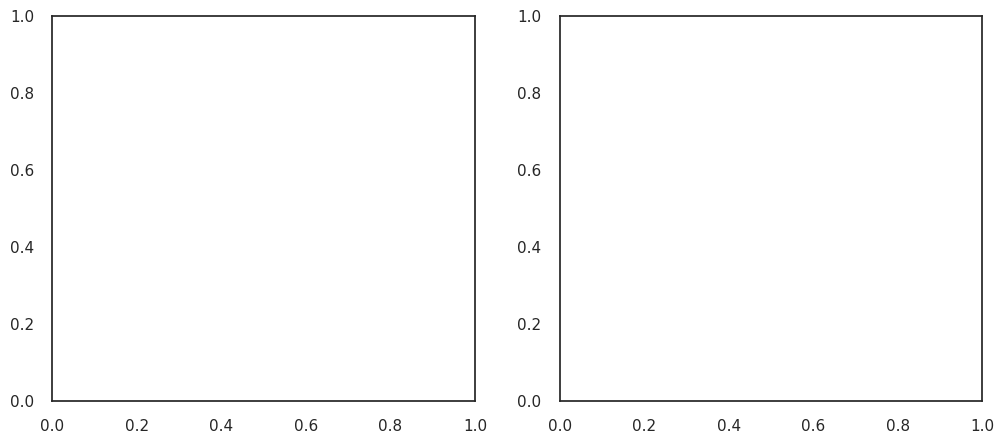

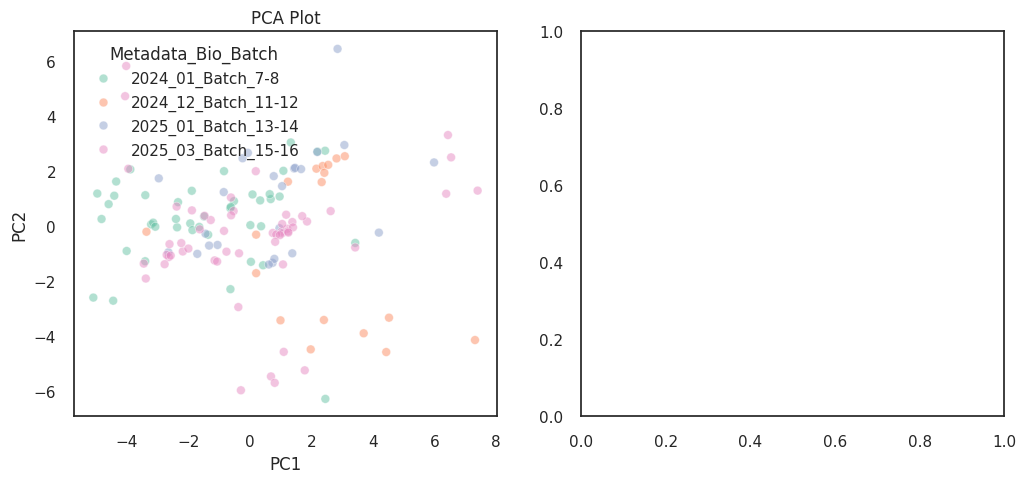

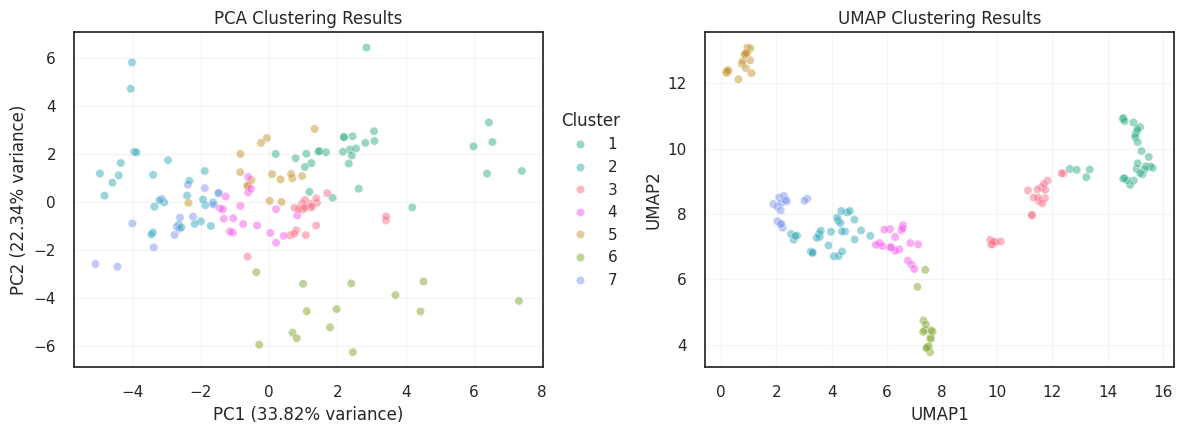

In [40]:
# Get unique clusters and create color palette
n_clusters = len(np.unique(dr_res_df["Metadata_cluster"]))
colors = sns.color_palette("husl", n_clusters)
color_map = {cluster: colors[i] for i, cluster in enumerate(dr_res_df["Metadata_cluster"].unique())}

fig, ax = plt.subplots(1,2, figsize=(12, 4.5))
# PCA plot
sns.scatterplot(
    dr_res_df,
    x="PC1",
    y="PC2",
    hue="Metadata_cluster",
    palette=color_map,
    ax=ax[0],
    alpha=.5,
    # legend=False
)
# for cluster in unique_clusters:
#     mask = np.array(clusters) == cluster
#     ax[0].scatter(data_pca[mask, 0], data_pca[mask, 1], 
#                  c=[color_map[cluster]], label=f'Cluster {cluster}',
#                  s=40, alpha=0.5)
ax[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} variance)')
ax[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} variance)')
ax[0].set_title('PCA Clustering Results')
ax[0].legend(bbox_to_anchor=(1.01, 0.5), loc='center left', title="Cluster", ncol=1)

# PCA plot
sns.scatterplot(
    dr_res_df,
    x="UMAP1",
    y="UMAP2",
    hue="Metadata_cluster",
    palette=color_map,
    ax=ax[1],
    alpha=.5,
    legend=False
)
# Add text labels for high-scoring points in PCA
high_score_mask = dr_res_df['Metadata_Altered_95th_perc_both_batches_GFP_ADJ']==True

# ax[1].get_legend().remove()

texts_pca = []
# for idx in dr_res_df[high_score_mask].index:
#    texts_pca.append(
#       ax[0].text(
#        dr_res_df.loc[idx, 'PC1'],
#        dr_res_df.loc[idx, 'PC2'],
#        str(idx),
#        fontsize=8
#    ))
# adjust_text(texts_pca, ax=ax[0], arrowprops=dict(arrowstyle='->', color='black', lw=0.5))

# Add text labels for high-scoring points in UMAP
texts_umap = []
# for idx in dr_res_df[high_score_mask].index:
#    texts_umap.append(ax[1].text(
#        dr_res_df.loc[idx, 'UMAP1'],
#        dr_res_df.loc[idx, 'UMAP2'],
#        str(idx),
#        fontsize=8
#    ))
# adjust_text(texts_umap, ax=ax[1], arrowprops=dict(arrowstyle='->', color='black', lw=0.5))

# for cluster in unique_clusters:
#     mask = np.array(clusters) == cluster
#     ax[1].scatter(embedding[mask, 0], embedding[mask, 1],
#                  c=[color_map[cluster]], label=f'Cluster {cluster}',
#                  s=40, alpha=0.5)

ax[1].set_xlabel('UMAP1')
ax[1].set_ylabel('UMAP2')
ax[1].set_title('UMAP Clustering Results')

ax[0].grid(alpha=.2)
ax[1].grid(alpha=.2)
plt.subplots_adjust(wspace=.3)
plt.tight_layout()
plt.show()

In [42]:
# # Plot UMAP
# fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# sns.scatterplot(data=pca_df.sort_values(by="Metadata_Bio_Batch"), alpha=.5,
#                 x="PC1", y="PC2", hue="Metadata_Bio_Batch", palette="Set2", s=40, ax=axes[0]) ## hue=variant_type, 
# # texts = []
# # for i, label in enumerate(group2_labels):
# #     if label in misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]:
# #         texts.append(ax.text(umap_result[i, 0], umap_result[i, 1], label, 
# #                      fontsize=6, fontweight='bold', color='black'))
# # adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax) ## 
# axes[0].set_title("PCA Plot")
# axes[0].set_xlabel("PC1")
# axes[0].set_ylabel("PC2")
# axes[0].legend(title="Metadata_Bio_Batch")

# # umap_df["Metadata_variant_type"] = well_profiles_plate_agg["Metadata_variant_type"].to_numpy()
# # umap_df["Metadata_control_type"] = well_profiles_plate_agg["Metadata_control_type"].to_numpy()

# # Plot UMAP
# sns.scatterplot(data=dr_res_df.sort_values(by="Metadata_Bio_Batch"), x="UMAP1", y="UMAP2", 
# hue="Metadata_Bio_Batch", palette="Set2", alpha=.5, s=30, ax=axes[1]) ## hue=variant_type, 
# # texts = []
# # for i, label in enumerate(group2_labels):
# #     if label in misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]:
# #         texts.append(ax.text(umap_result[i, 0], umap_result[i, 1], label, 
# #                      fontsize=6, fontweight='bold', color='black'))
# # adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax) ## 
# axes[1].set_title("UMAP Plot")
# axes[1].set_xlabel("UMAP1")
# axes[1].set_ylabel("UMAP2")
# axes[1].legend(title="Metadata_Bio_Batch")
# plt.tight_layout()
# plt.show()

In [43]:
# Get cluster order from UMAP clustering
cluster_order = dr_res_df.sort_values('Metadata_cluster')['Metadata_cluster'].unique()

# Create cluster color mapping
n_clusters = len(np.unique(dr_res_df["Metadata_cluster"]))
cluster_colors = sns.color_palette("husl", n_clusters)
cluster_color_map = {cluster: cluster_colors[i] for i, cluster in enumerate(dr_res_df["Metadata_cluster"].unique())}

# Create ordered list based on clusters, then by score within clusters
ordered_variants = []
cluster_labels = []

for cluster in cluster_order:
#    print(cluster)
   cluster_variants = dr_res_df[dr_res_df['Metadata_cluster']==cluster].sort_values('Metadata_AUROC_Mean_GFP_ADJ', ascending=False).index.tolist()
   ordered_variants.extend(cluster_variants)
#    print(len(ordered_variants))
   cluster_labels.extend([cluster] * len(cluster_variants))

available_variants = []
available_cluster_labels = []
for i, variant in enumerate(ordered_variants):
   if variant in dr_res_df.sort_values('Metadata_AUROC_Mean_GFP_ADJ').index:
       available_variants.append(variant)
       available_cluster_labels.append(cluster_labels[i])

## Combine both color arrays as separate columns
row_colors_df = pd.DataFrame(index=ordered_variants)
row_colors_df['Cluster'] = [cluster_color_map[cluster] for cluster in available_cluster_labels]
# row_colors_df['AUROC_GFP'] = list(auroc_colors)

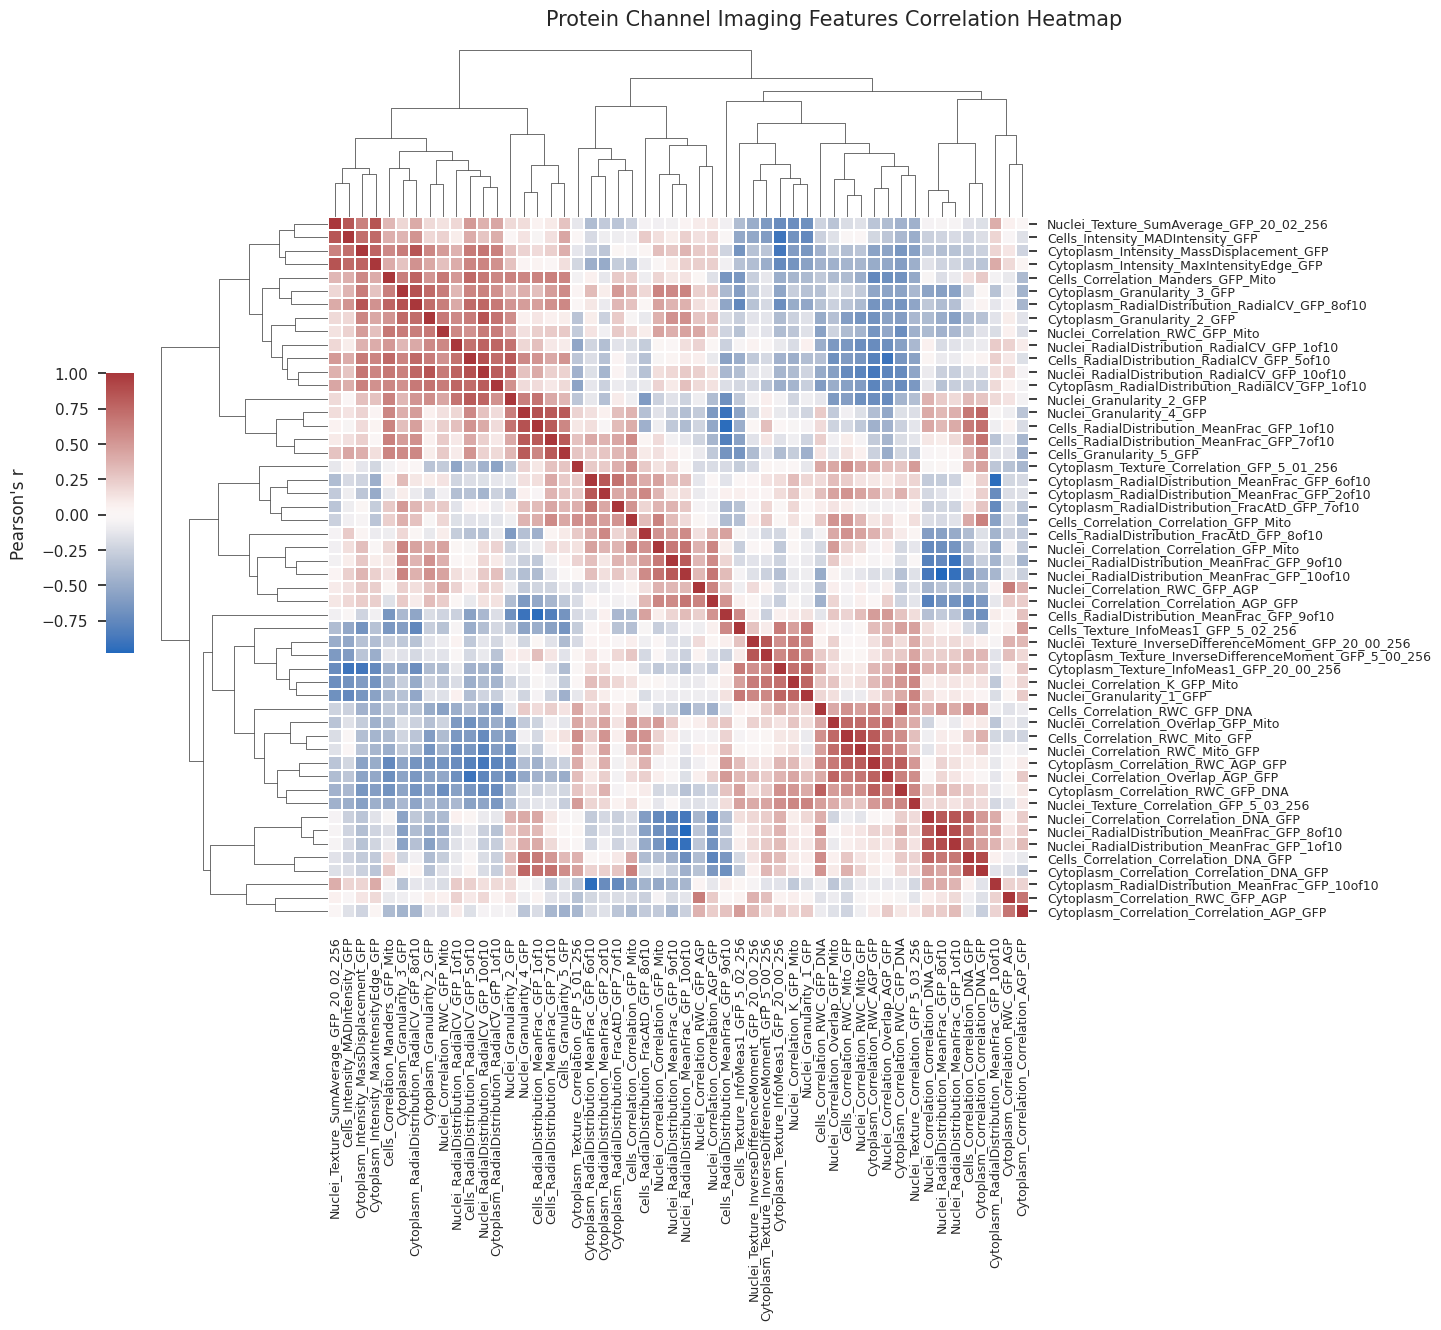

In [44]:
corr_df = df.loc[[idx for idx in row_colors_df.index if idx in misloc_alleles],:].corr()
g = sns.clustermap(
    data=corr_df,
    cmap="vlag",
    cbar_pos=(-.02, 0.55, 0.02, 0.2),
    yticklabels=1, xticklabels=1,
    square=True,
    figsize=(14,14),
    # annot=True, fmt=".2f",
    linewidth=.05, 
    # ax=ax
)
g.fig.suptitle("Protein Channel Imaging Features Correlation Heatmap", fontsize=15, y=1.01)
g.cax.yaxis.set_label_position('left')
g.cax.yaxis.set_ticks_position('left')
g.cax.set_ylabel(r"Pearson's r", labelpad=10) ##pearman's $\rho$
g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xticklabels(), fontsize=9)
g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_yticklabels(), fontsize=9)
plt.show()

col_order = list(corr_df.columns[g.dendrogram_col.reordered_ind])

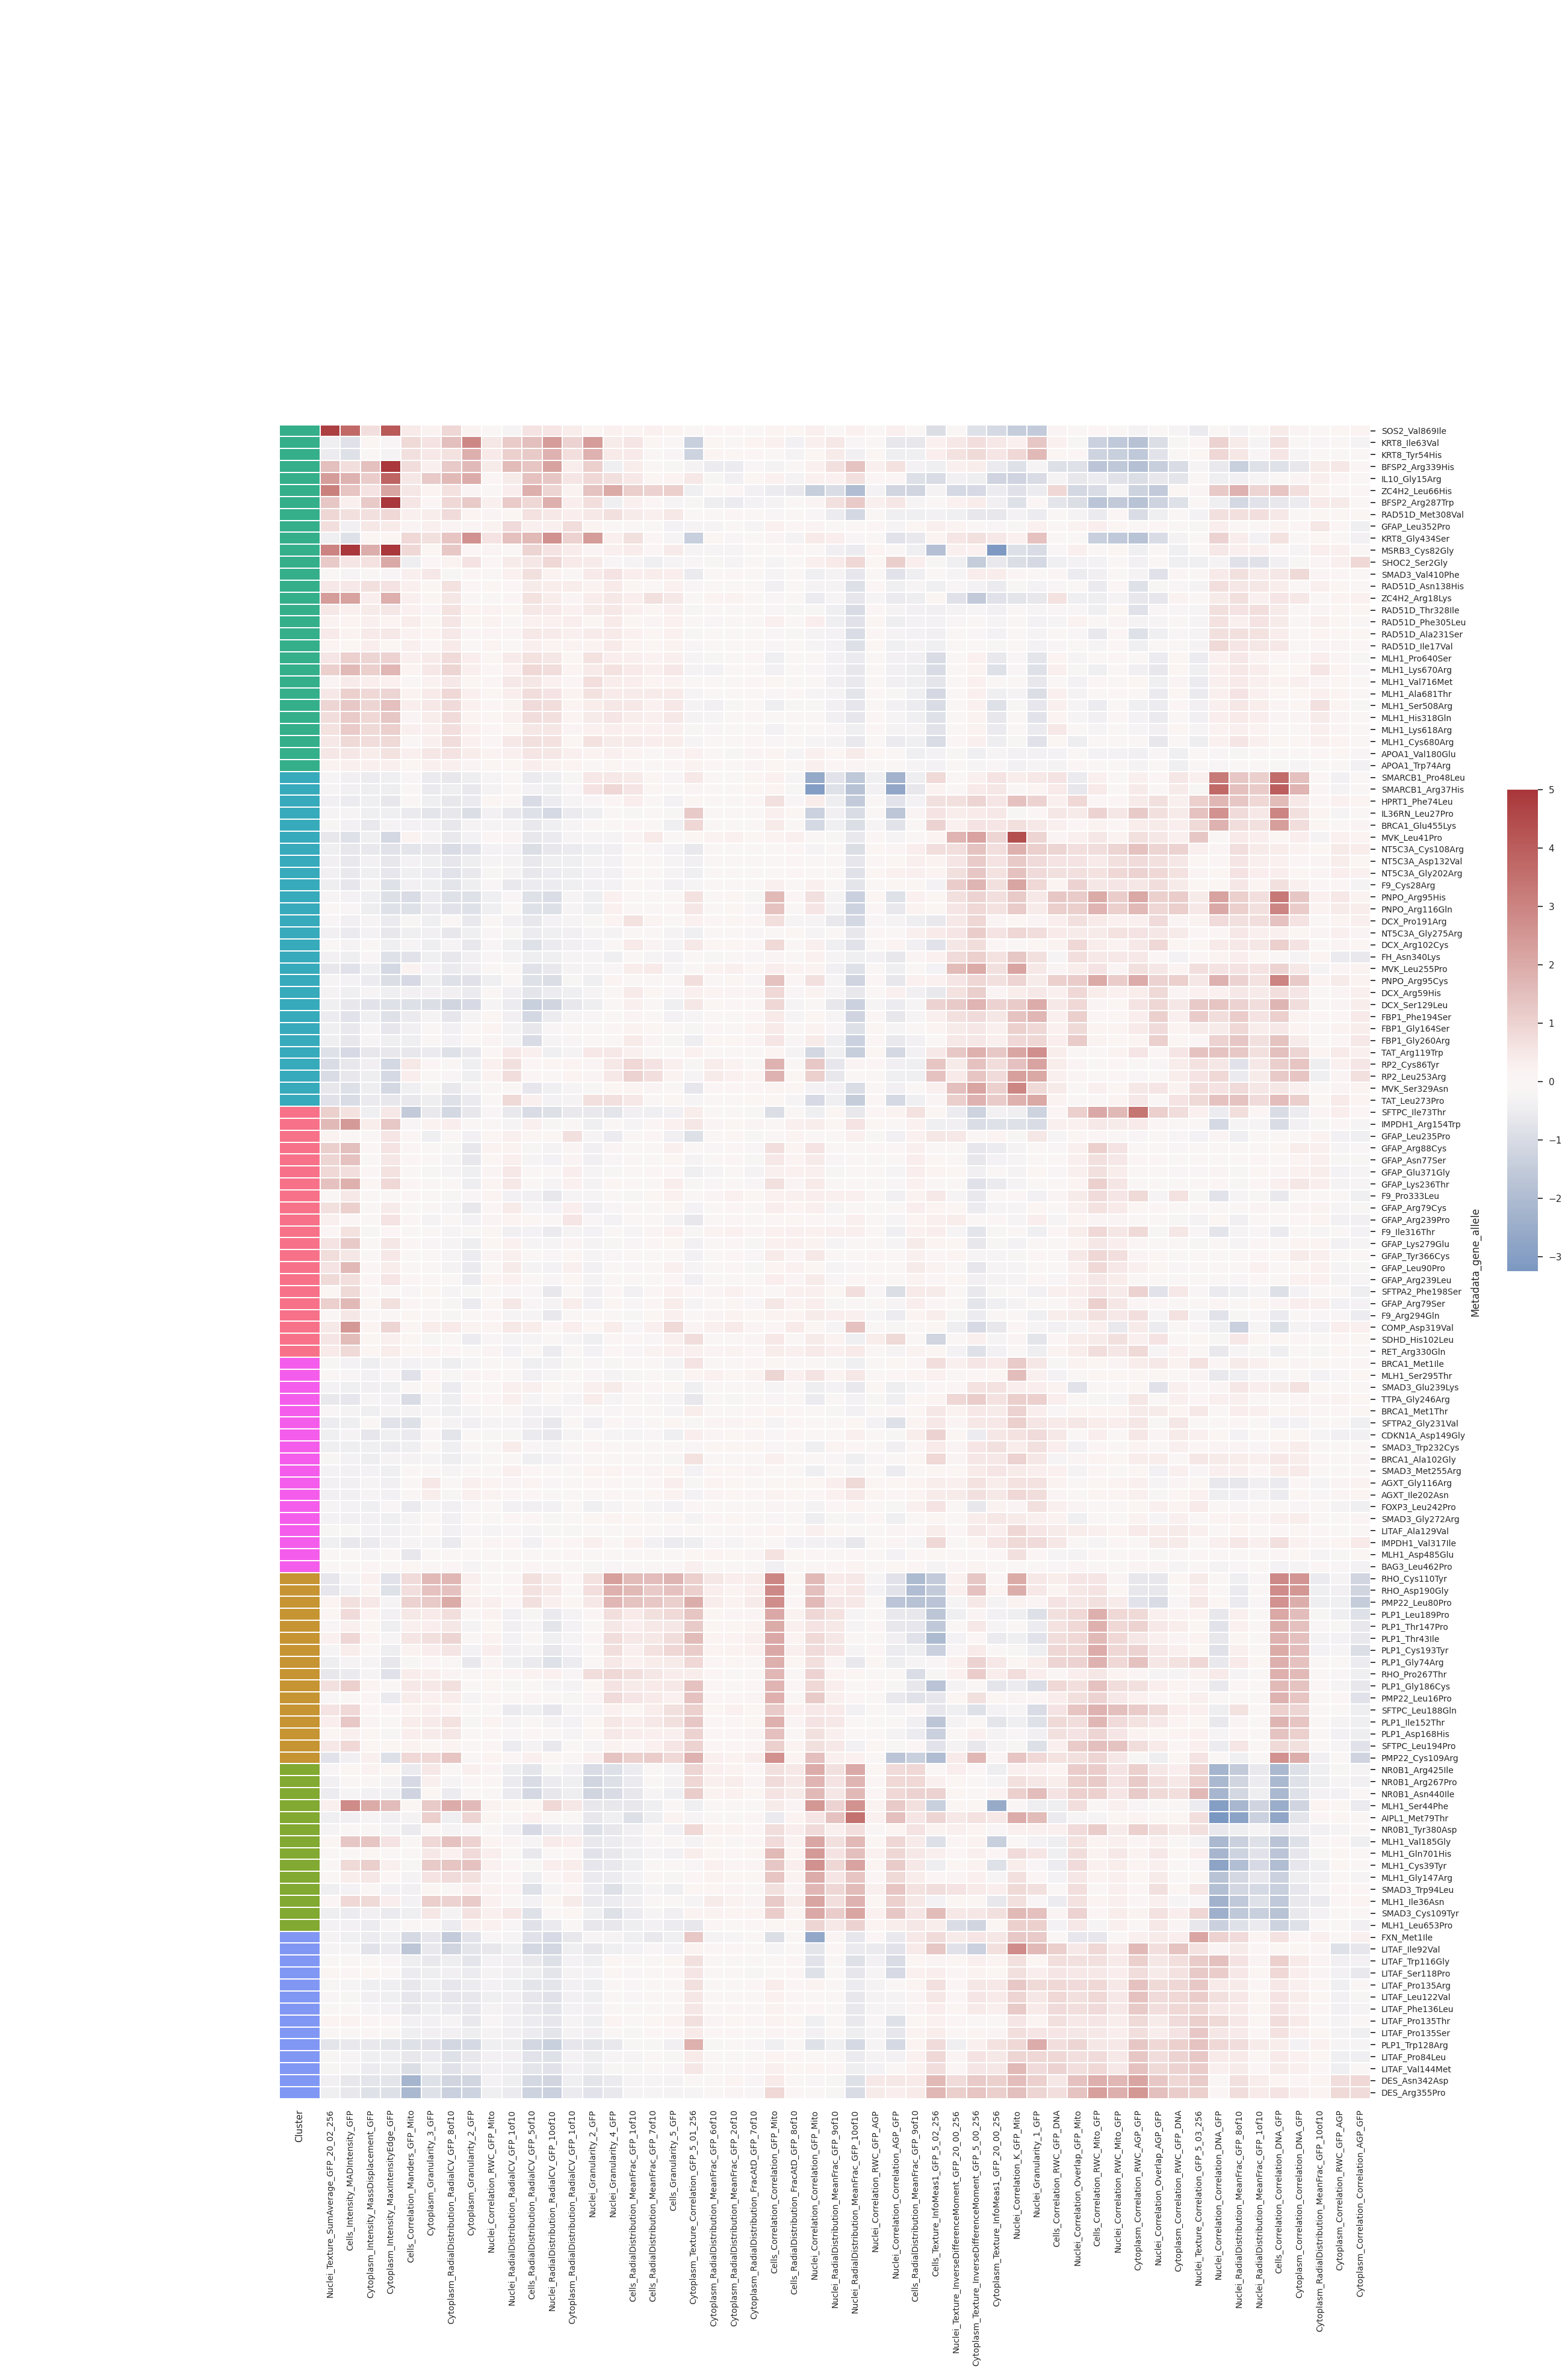

In [45]:
g = sns.clustermap(
    data=df.loc[[idx for idx in row_colors_df.index if idx in misloc_alleles],col_order],
    cmap="vlag",
    center=0,
    row_colors=row_colors_df.loc[[idx for idx in row_colors_df.index if idx in misloc_alleles],:],
    row_cluster=False,
    col_cluster=False,
    cbar_pos=(1.005, 0.47, 0.02, 0.2),
    figsize=(25, 40),
    yticklabels=1, 
    linewidth=.05, 
    # xticklabels=1,
    # dendrogram_ratio=0
)
g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xticklabels(), fontsize=10)
g.ax_heatmap.set_yticklabels(g.ax_heatmap.get_yticklabels(), fontsize=10)
plt.show()

In [47]:
dr_res_df.to_csv("../../3_outputs/variant_clustering_results.csv")
corr_df.loc[col_order, col_order].to_csv("../../3_outputs/protein_features_corr_mat.csv")
df.loc[[idx for idx in row_colors_df.index if idx in misloc_alleles],col_order].to_csv("../../3_outputs/variant_protein_feature_matrix.csv")